In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "utils"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import cathodeparams, anodeparams, membraneparams, cellparams

## Test selection

Set `TEST_NO` to the test number whose fitted HFR (membrane) and, if available, E-cell
(cathode/anode kinetics) parameters should be loaded. `results/test fitting/global/` currently
only has an E-cell fit covering test 16 — for any other test the notebook falls back to the
`cathodeparams`/`anodeparams` defaults and prints a warning.

In [2]:
# -- Test to inspect ---------------------------------------------------------
TEST_NO = 16

# -- Solver settings ----------------------------------------------------------
TF     = 1800   # [s] max simulated time per operating point
RTOL   = 1e-5
STRIDE = 1       # subsample experimental current points (1 = use all)
N_FILL = 0       # extra interior current points per gap, for a smoother HFR curve (0 = off)

## Load this test's HFR + E-cell fits

In [3]:
def _resolve_ecell_params(test_no: int):
    """k_ca (cathode reaction_rate_constant) and j0_an (anode j_0) for this
    test, resolved in priority order:
      1) a per-test Stage-2 fit saved in the test's own folder
      2) the most recent global Stage-1 fit that covered this test
    Returns (k_ca, j0_an, source_filename) or (None, None, None) if no
    E-cell fit is available for this test yet.
    """
    test_dir = ROOT / "results" / "test fitting" / f"test {test_no}"

    stage2 = sorted(test_dir.glob(f"global_j0an_test{test_no}_*.json"))
    if stage2:
        with open(stage2[-1]) as f:
            fit = json.load(f)
        return float(fit["params"]["k_ca"]), float(fit["params"]["j0_an"]), stage2[-1].name

    global_dir  = ROOT / "results" / "test fitting" / "global"
    global_fits = sorted(global_dir.glob("global_k_ca_*.json"))
    for gp in reversed(global_fits):   # most recent first
        with open(gp) as f:
            fit = json.load(f)
        j0_dict = fit["params"].get("j0_an", {})
        if str(test_no) in j0_dict:
            return float(fit["params"]["k_ca"]), float(j0_dict[str(test_no)]), gp.name

    return None, None, None


# -- HFR (membrane) fit --------------------------------------------------------
fit_dir  = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
fit_path = sorted(fit_dir.glob(f"HFR_fit_test{TEST_NO}_*.json"))[-1]
with open(fit_path) as f:
    _hfr = json.load(f)
_p, _s = _hfr["params"], _hfr["settings"]

hfr_params = dict(
    k_sorp_vw   = _p["k_vw_sorp"],
    k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"],
    k_sorp_lw   = _p["k_lw_sorp"],
    k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"],
    k_ca_lw     = _p["k_ca"],
    sf_D        = _s["sf_D"],
    vanadium_uptake = _s.get("vanadium_uptake", False),
)
R_EXTRA = _p["R_extra (\u03a9\u00b7cm\u00b2)"] / 1e4   # \u03a9\u00b7cm\u00b2 -> \u03a9\u00b7m\u00b2

# -- E-cell (cathode/anode kinetics) fit, if one exists for this test ---------
k_ca, j0_an, ecell_source = _resolve_ecell_params(TEST_NO)
if k_ca is None:
    print(f"[WARNING] No E-cell fit found for test {TEST_NO} \u2014 "
          f"using cathodeparams/anodeparams defaults.")
    k_ca  = cathodeparams.reaction_rate_constant
    j0_an = anodeparams.j_0

# -- Experimental operating point + current sweep ------------------------------
csv = ROOT / "data" / "experimental" / "HFR.csv"
_df = pd.read_csv(csv)
d   = _df[_df["test_no"] == TEST_NO]
soc = float(d["SOC"].iloc[0])
T   = float(d["T(\u00b0C)"].iloc[0])
Q_v = float(d["Q_v (ml/min)"].iloc[0])

j_charge    = d[d["mode"] == "charge"]   ["j_appl (A/m2)"].values[::STRIDE]
j_discharge = d[d["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE]
HFR_exp_ch  = d[d["mode"] == "charge"]   ["value (ohm cm2)"].values[::STRIDE]
HFR_exp_dis = d[d["mode"] == "discharge"]["value (ohm cm2)"].values[::STRIDE]

cfg = dict(
    soc=soc, T=T, Q_v=Q_v,
    j_charge=j_charge, j_discharge=j_discharge,
    HFR_exp_ch=HFR_exp_ch, HFR_exp_dis=HFR_exp_dis,
    hfr=hfr_params, R_EXTRA=R_EXTRA,
    k_ca=k_ca, j0_an=j0_an,
)

print(f"Test {TEST_NO}: SOC={soc:.0%}  T={T}\u00b0C  Q_v={Q_v} ml/min")
print(f"  HFR fit    -> {fit_path.name}")
print(f"  E-cell fit -> {ecell_source or '(defaults)'}")
print(f"  k_ca={k_ca:.3e}  j0_an={j0_an:.3e}  R_extra={R_EXTRA*1e4:.4f} \u03a9\u00b7cm\u00b2")
print(f"  {len(j_charge)} charge / {len(j_discharge)} discharge experimental points")

Test 16: SOC=50%  T=32.0°C  Q_v=45.0 ml/min
  HFR fit    -> HFR_fit_test16_20260817_155113.json
  E-cell fit -> global_k_ca_fit_32.json
  k_ca=1.144e-09  j0_an=3.544e+03  R_extra=0.0310 Ω·cm²
  12 charge / 13 discharge experimental points


## Run the HFR simulation across the experimental current sweep

Each steady-state DAE solve already yields the converged membrane water-content (λ) profile
as part of computing HFR, so the ionomer behaviour below reuses these same runs instead of a
separate resistance calculation.

In [4]:
def _apply_params(cfg: dict) -> None:
    """Apply this test's membrane, R_extra and kinetic params to the module-level
    singleton dataclasses that build_cell() reads from."""
    h = cfg["hfr"]
    membraneparams.k_sorp_vw   = h["k_sorp_vw"]
    membraneparams.k_desorp_vw = h["k_desorp_vw"]
    membraneparams.k_sorp_lw   = h["k_sorp_lw"]
    membraneparams.k_desorp_lw = h["k_desorp_lw"]
    membraneparams.k_ca_lw     = h["k_ca_lw"]
    membraneparams.sf_D        = h["sf_D"]
    cellparams.vanadium_uptake = h["vanadium_uptake"]
    cathodeparams.reaction_rate_constant = cfg["k_ca"]
    anodeparams.j_0                      = cfg["j0_an"]


def run_sim(j_appl: float, cfg: dict):
    """Run one steady-state operating point and return HFR plus anode state values."""
    _apply_params(cfg)
    cell, y0, yp0 = build_cell(cfg["soc"], j_appl, cfg["T"], cfg["Q_v"])
    atol          = build_atol(cell)
    jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)
    t0 = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    cell.dae_residual_full_cell(sol.t[-1], sol.y[:, -1], sol.yp[:, -1])
    if sol.t[-1] < 0.99 * TF:
        print(f"  Warning: t_final={sol.t[-1]:.1f} s (event triggered)")

    state       = cell.split_state(sol.y[:, -1])
    anode_state = state["anode"]
    lam_profile = state["membrane"][:, 0]
    x_mem       = cell.mesh.membrane_mesh.x_grid
    s_acl       = float(anode_state[2])
    s_agdl      = float(anode_state[6])
    c_vw_acl    = float(anode_state[0])
    c_vw_agdl   = float(anode_state[4])

    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = sum(dx_ca / (sigma_ca + kappa_io_ca))

    kappa_io_m = cell.membrane.kappa_io
    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = sum(dx_m / kappa_io_m)

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC
    HFR    = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + cfg["R_EXTRA"]) * 1e4

    print(f"  j={j_appl:+8.0f} A/m²  HFR={HFR:.4f} Ω·cm²  ({time.time()-t0:.1f}s)")
    return HFR, lam_profile, x_mem, kappa_io_m, dx_m, s_acl, s_agdl, c_vw_acl, c_vw_agdl


def interior_points(arr, n=1):
    """n equally-spaced interior points between each consecutive pair in arr."""
    if n == 0 or len(arr) < 2:
        return np.array([])
    pts = []
    for a, b in zip(arr[:-1], arr[1:]):
        pts.extend(np.linspace(a, b, n + 2)[1:-1])
    return np.array(pts)

In [5]:
print(f"Test {TEST_NO}  |  k_ca={cfg['k_ca']:.3e}  j0_an={cfg['j0_an']:.3e}")

print("-- Charge --")
_res_ch = [run_sim(float(j), cfg) for j in cfg["j_charge"]]
HFR_ch  = [r[0] for r in _res_ch]
lam_ch  = [r[1] for r in _res_ch]
x_mem   = _res_ch[0][2]
kappa_ch = [r[3] for r in _res_ch]
dx_m     = _res_ch[0][4]
s_acl_ch = [r[5] for r in _res_ch]
s_agdl_ch = [r[6] for r in _res_ch]
c_vw_acl_ch = [r[7] for r in _res_ch]
c_vw_agdl_ch = [r[8] for r in _res_ch]

j_ch_fill   = interior_points(cfg["j_charge"], n=N_FILL)
HFR_ch_fill = [run_sim(float(j), cfg)[0] for j in j_ch_fill]
j_model_ch   = np.concatenate([cfg["j_charge"], j_ch_fill])
HFR_model_ch = np.concatenate([HFR_ch, HFR_ch_fill])
idx = np.argsort(j_model_ch)
j_model_ch, HFR_model_ch = j_model_ch[idx], HFR_model_ch[idx]

print("-- Discharge --")
_res_dis = [run_sim(-float(j), cfg) for j in cfg["j_discharge"]]
HFR_dis  = [r[0] for r in _res_dis]
lam_dis  = [r[1] for r in _res_dis]
kappa_dis = [r[3] for r in _res_dis]
dx_m_dis  = [r[4] for r in _res_dis]
s_acl_dis = [r[5] for r in _res_dis]
s_agdl_dis = [r[6] for r in _res_dis]
c_vw_acl_dis = [r[7] for r in _res_dis]
c_vw_agdl_dis = [r[8] for r in _res_dis]

j_dis_fill   = interior_points(cfg["j_discharge"], n=N_FILL)
HFR_dis_fill = [run_sim(-float(j), cfg)[0] for j in j_dis_fill]
j_model_dis   = np.concatenate([cfg["j_discharge"], j_dis_fill])
HFR_model_dis = np.concatenate([HFR_dis, HFR_dis_fill])
idx = np.argsort(j_model_dis)
j_model_dis, HFR_model_dis = j_model_dis[idx], HFR_model_dis[idx]

HFR_exp_all = np.concatenate([cfg["HFR_exp_ch"], cfg["HFR_exp_dis"]])
HFR_sim_all = np.array(HFR_ch + HFR_dis)
mse = float(np.mean((HFR_sim_all - HFR_exp_all) ** 2))
ape = float(np.mean(np.abs((HFR_sim_all - HFR_exp_all) / HFR_exp_all)) * 100)
print(f"\nMSE={mse:.6f}  RMSE={mse**0.5:.4f} Ω·cm²  APE={ape:.2f}%")

sim_results = dict(
    j_model_ch=j_model_ch, HFR_model_ch=HFR_model_ch,
    j_model_dis=j_model_dis, HFR_model_dis=HFR_model_dis,
    HFR_sim_ch=HFR_ch, HFR_sim_dis=HFR_dis,
    kappa_ch=kappa_ch, kappa_dis=kappa_dis, dx_m=dx_m, dx_m_dis=dx_m_dis,
    lam_ch=lam_ch, lam_dis=lam_dis, x_mem=x_mem,
    s_acl_ch=s_acl_ch, s_acl_dis=s_acl_dis,
    s_agdl_ch=s_agdl_ch, s_agdl_dis=s_agdl_dis,
    c_vw_acl_ch=c_vw_acl_ch, c_vw_acl_dis=c_vw_acl_dis,
    c_vw_agdl_ch=c_vw_agdl_ch, c_vw_agdl_dis=c_vw_agdl_dis,
    mse=mse, ape=ape,
)

Test 16  |  k_ca=1.144e-09  j0_an=3.544e+03
-- Charge --
  j=     +45 A/m²  HFR=0.4819 Ω·cm²  (6.3s)
  j=    +258 A/m²  HFR=0.4752 Ω·cm²  (3.7s)
  j=    +494 A/m²  HFR=0.4687 Ω·cm²  (5.6s)
  j=    +753 A/m²  HFR=0.4617 Ω·cm²  (3.8s)
  j=   +1034 A/m²  HFR=0.4536 Ω·cm²  (24.3s)
  j=   +1247 A/m²  HFR=0.4525 Ω·cm²  (25.6s)
  j=   +1494 A/m²  HFR=0.4514 Ω·cm²  (25.8s)
Call 20000: t=94.471580, max|res|=2.445111e-02
  j=   +1742 A/m²  HFR=0.4506 Ω·cm²  (32.8s)
Call 20000: t=76.633565, max|res|=1.798646e-03
  j=   +2000 A/m²  HFR=0.4498 Ω·cm²  (34.3s)
Call 20000: t=62.074249, max|res|=4.389642e-02
  j=   +2506 A/m²  HFR=0.4488 Ω·cm²  (56.9s)
Call 20000: t=38.744673, max|res|=7.975914e-05
Call 40000: t=75.830518, max|res|=2.069558e-03
  j=   +3011 A/m²  HFR=0.4485 Ω·cm²  (82.4s)
Call 20000: t=32.188115, max|res|=1.745762e-04
Call 40000: t=55.004130, max|res|=1.233779e-06
Call 60000: t=63.183977, max|res|=4.616194e-03
  j=   +3494 A/m²  HFR=0.4484 Ω·cm²  (126.4s)
-- Discharge --
  j=    -258 A

## HFR fit-quality check

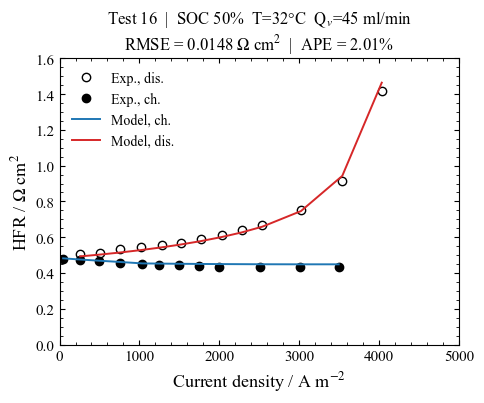

Saved -> <repo>\figures\ionomer_test16_HFR.pdf


In [6]:
plt.rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset':  'stix',
    'font.size':         12,
    'axes.labelsize':    13,
    'axes.titlesize':    12,
    'xtick.labelsize':   11,
    'ytick.labelsize':   11,
    'legend.fontsize':   10,
    'axes.linewidth':    0.8,
    'xtick.direction':   'in',
    'ytick.direction':   'in',
    'xtick.top':         True,
    'ytick.right':       True,
    'lines.linewidth':   1.4,
})

fig, ax = plt.subplots(figsize=(5, 4.2))

ax.plot(cfg["j_discharge"], cfg["HFR_exp_dis"],
        'o', ms=6, mfc='none', mec='k', mew=1.0, label='Exp., dis.')
ax.plot(cfg["j_charge"],    cfg["HFR_exp_ch"],
        'o', ms=6, mfc='k',    mec='k', mew=1.0, label='Exp., ch.')
ax.plot(sim_results["j_model_ch"],  sim_results["HFR_model_ch"],  '-', color='C0', label='Model, ch.')
ax.plot(sim_results["j_model_dis"], sim_results["HFR_model_dis"], '-', color='C3', label='Model, dis.')

ax.set_xlabel(r'Current density / A m$^{-2}$')
ax.set_ylabel(r'HFR / $\Omega$ cm$^2$')
ax.set_xlim(0, 5000)
ax.set_ylim(0, 1.6)
ax.set_title(
    f"Test {TEST_NO}  |  SOC {cfg['soc']:.0%}  T={cfg['T']:.0f}\u00b0C  Q$_v$={cfg['Q_v']:.0f} ml/min\n"
    f"RMSE = {sim_results['mse']**0.5:.4f} $\Omega$ cm$^2$  |  APE = {sim_results['ape']:.2f}%"
)
ax.legend(frameon=False)
ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

fig.tight_layout()
out_path = ROOT / "figures" / f"ionomer_test{TEST_NO}_HFR.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {out_path}")

## Membrane water-content (λ) profile

λ(x) across the membrane thickness at the final (steady) simulated state for every
experimental current density, x=0 at the cathode interface and x=1 at the anode interface.

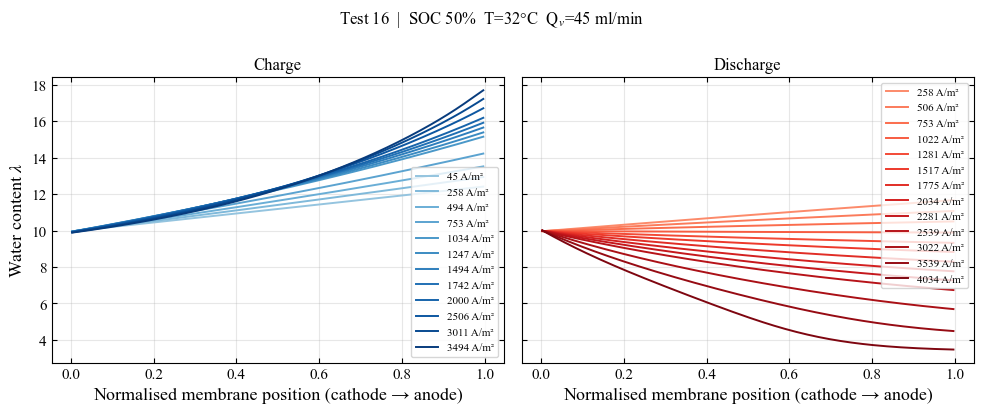

Saved -> <repo>\figures\ionomer_test16_lambda.pdf


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)

nc, nd = len(cfg["j_charge"]), len(cfg["j_discharge"])
colors_c = plt.cm.Blues(np.linspace(0.4, 0.95, max(nc, 1)))
colors_d = plt.cm.Reds(np.linspace(0.4, 0.95, max(nd, 1)))

for lam, j, c in zip(sim_results["lam_ch"], cfg["j_charge"], colors_c):
    axes[0].plot(sim_results["x_mem"], lam, color=c, label=f'{j:.0f} A/m\u00b2')
axes[0].set_xlabel('Normalised membrane position (cathode \u2192 anode)')
axes[0].set_ylabel(r'Water content $\lambda$')
axes[0].set_title('Charge')
axes[0].legend(fontsize=8, loc='best')
axes[0].grid(True, alpha=0.3)

for lam, j, c in zip(sim_results["lam_dis"], cfg["j_discharge"], colors_d):
    axes[1].plot(sim_results["x_mem"], lam, color=c, label=f'{j:.0f} A/m\u00b2')
axes[1].set_xlabel('Normalised membrane position (cathode \u2192 anode)')
axes[1].set_title('Discharge')
axes[1].legend(fontsize=8, loc='best')
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f"Test {TEST_NO}  |  SOC {cfg['soc']:.0%}  T={cfg['T']:.0f}\u00b0C  Q$_v$={cfg['Q_v']:.0f} ml/min",
    fontsize=12,
)
fig.tight_layout()
out_path = ROOT / "figures" / f"ionomer_test{TEST_NO}_lambda.pdf"
fig.savefig(out_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {out_path}")

In [8]:
def cumulative_R_linear(kappa, dx_m):
    """Cumulative R(x) [Ohm cm^2] assuming kappa varies LINEARLY between the two
    interface values. Same node edges as np.concatenate([[0], np.cumsum(dx_m/kappa)])*1e4,
    so it overlays directly. Equals the resolved curve iff the profile is linear."""
    dx_m = np.asarray(dx_m, float)
    L = dx_m.sum()
    x_edges = np.concatenate([[0.0], np.cumsum(dx_m)])
    k0, kL = float(kappa[0]), float(kappa[-1])
    if abs(kL - k0) <= 1e-9 * max(abs(k0), abs(kL)):
        return x_edges / (0.5 * (k0 + kL)) * 1e4
    k_x = k0 + (kL - k0) * x_edges / L
    return (L / (kL - k0)) * np.log(k_x / k0) * 1e4

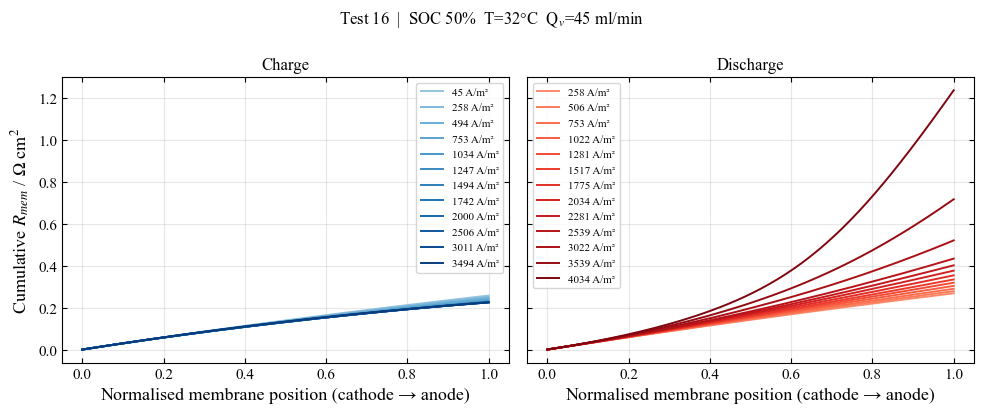

Saved -> <repo>\figures\ionomer_test16_cumul_R.pdf


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)

dx_m = sim_results["dx_m"]
# x positions at node edges (for step-like cumulative plot)
x_edges = np.concatenate([[0], np.cumsum(dx_m)])
x_norm  = x_edges / x_edges[-1]  # normalised 0→1

nc = len(cfg["j_charge"])
nd = len(cfg["j_discharge"])
colors_c = plt.cm.Blues(np.linspace(0.4, 0.95, max(nc, 1)))
colors_d = plt.cm.Reds(np.linspace(0.4, 0.95, max(nd, 1)))

for kappa, j, c in zip(sim_results["kappa_ch"], cfg["j_charge"], colors_c):
    dR = dx_m / kappa * 1e4  # per-node resistance [Ω·cm²]
    R_cumul = np.concatenate([[0], np.cumsum(dR)])
    axes[0].plot(x_norm, R_cumul, color=c, label=f'{j:.0f} A/m²')

axes[0].set_xlabel('Normalised membrane position (cathode → anode)')
axes[0].set_ylabel(r'Cumulative $R_{mem}$ / $\Omega$ cm$^2$')
axes[0].set_title('Charge')
axes[0].legend(fontsize=8, loc='best')
axes[0].grid(True, alpha=0.3)

for kappa, j, c in zip(sim_results["kappa_dis"], cfg["j_discharge"], colors_d):
    dR = dx_m / kappa * 1e4
    R_cumul = np.concatenate([[0], np.cumsum(dR)])
    axes[1].plot(x_norm, R_cumul, color=c, label=f'{j:.0f} A/m²')

axes[1].set_xlabel('Normalised membrane position (cathode → anode)')
axes[1].set_title('Discharge')
axes[1].legend(fontsize=8, loc='best')
axes[1].grid(True, alpha=0.3)

fig.suptitle(
    f"Test {TEST_NO}  |  SOC {cfg['soc']:.0%}  T={cfg['T']:.0f}°C  Q$_v$={cfg['Q_v']:.0f} ml/min",
    fontsize=12,
)
fig.tight_layout()
out_path = ROOT / "figures" / f"ionomer_test{TEST_NO}_cumul_R.pdf"
fig.savefig(out_path, bbox_inches='tight')
plt.show()
print(f"Saved -> {out_path}")

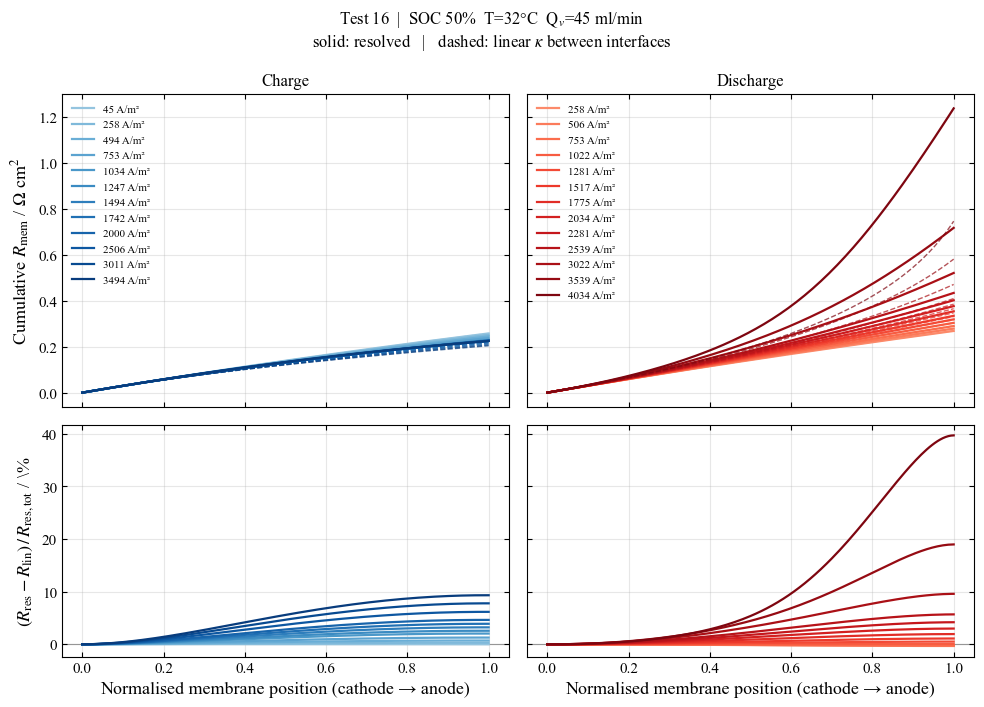

mode        i [A/m2]    R_res    R_lin  delta [%]
Charge            45   0.2580   0.2580        0.0
Charge           258   0.2514   0.2506        0.3
Charge           494   0.2449   0.2432        0.7
Charge           753   0.2380   0.2349        1.3
Charge          1034   0.2299   0.2252        2.0
Charge          1247   0.2288   0.2230        2.6
Charge          1494   0.2278   0.2205        3.2
Charge          1742   0.2270   0.2181        3.9
Charge          2000   0.2263   0.2158        4.6
Charge          2506   0.2254   0.2115        6.2
Charge          3011   0.2252   0.2076        7.8
Charge          3494   0.2252   0.2043        9.3
Discharge        258   0.2688   0.2695       -0.3
Discharge        506   0.2789   0.2798       -0.3
Discharge        753   0.2902   0.2909       -0.2
Discharge       1022   0.3041   0.3040        0.1
Discharge       1281   0.3193   0.3176        0.5
Discharge       1517   0.3349   0.3312        1.1
Discharge       1775   0.3544   0.3475        1.9


In [12]:
dx_m   = sim_results["dx_m"]
x_edges = np.concatenate([[0], np.cumsum(dx_m)])
x_norm  = x_edges / x_edges[-1]
 
colors_c = plt.cm.Blues(np.linspace(0.4, 0.95, max(len(cfg["j_charge"]), 1)))
colors_d = plt.cm.Reds( np.linspace(0.4, 0.95, max(len(cfg["j_discharge"]), 1)))
 
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharex=True, sharey='row',
                         gridspec_kw=dict(height_ratios=[1.35, 1]))
 
summary = []
for col, (key, jkey, colors, title) in enumerate([
        ("kappa_ch",  "j_charge",    colors_c, "Charge"),
        ("kappa_dis", "j_discharge", colors_d, "Discharge")]):
 
    for kappa, j, c in zip(sim_results[key], cfg[jkey], colors):
        R_res = np.concatenate([[0], np.cumsum(dx_m / kappa)]) * 1e4
        R_lin = cumulative_R_linear(kappa, dx_m)
 
        axes[0, col].plot(x_norm, R_res, color=c, lw=1.6, label=f"{j:.0f} A/m²")
        axes[0, col].plot(x_norm, R_lin, color=c, ls="--", lw=1.0, alpha=0.7)
 
        # departure, normalised by the TOTAL resolved resistance (no 0/0 at x=0)
        delta = (R_res - R_lin) / R_res[-1] * 100
        axes[1, col].plot(x_norm, delta, color=c, lw=1.6)
 
        summary.append((title, j, R_res[-1], R_lin[-1], delta[-1]))
 
    axes[0, col].set_title(title)
    axes[0, col].legend(fontsize=8, loc="upper left", frameon=False)
    axes[1, col].axhline(0, color="0.55", lw=0.8, zorder=0)
    axes[1, col].set_xlabel("Normalised membrane position (cathode → anode)")
    for r in (0, 1):
        axes[r, col].grid(True, alpha=0.3)
 
axes[0, 0].set_ylabel(r"Cumulative $R_\mathrm{mem}$ / $\Omega$ cm$^2$")
axes[1, 0].set_ylabel(r"$(R_\mathrm{res}-R_\mathrm{lin})\,/\,R_\mathrm{res,tot}$ / \%")
 
fig.suptitle(
    f"Test {TEST_NO}  |  SOC {cfg['soc']:.0%}  T={cfg['T']:.0f}°C  Q$_v$={cfg['Q_v']:.0f} ml/min\n"
    "solid: resolved   |   dashed: linear $\\kappa$ between interfaces",
    fontsize=12,
)
fig.tight_layout()
out_path = ROOT / "figures" / f"ionomer_test{TEST_NO}_cumul_R.pdf"
fig.savefig(out_path, bbox_inches="tight", dpi=600)
plt.show()
 
print(f"{'mode':10s}{'i [A/m2]':>10s}{'R_res':>9s}{'R_lin':>9s}{'delta [%]':>11s}")
for mode, j, rr, rl, d in summary:
    print(f"{mode:10s}{j:10.0f}{rr:9.4f}{rl:9.4f}{d:11.1f}")
print(f"Saved -> {out_path}")

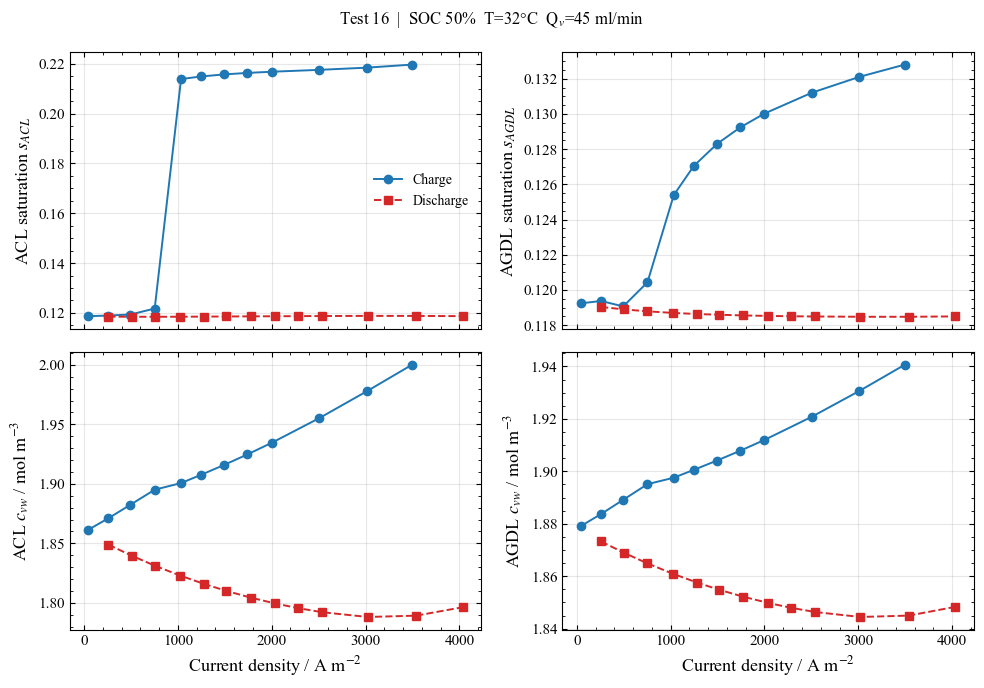

Saved -> <repo>\figures\ionomer_test16_anode_state.pdf


In [11]:
# -- Anode water state versus current density -------------------------------
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex="col")

series = [
    ("s_acl_ch", "s_acl_dis", r"ACL saturation $s_{ACL}$", axes[0, 0]),
    ("s_agdl_ch", "s_agdl_dis", r"AGDL saturation $s_{AGDL}$", axes[0, 1]),
    ("c_vw_acl_ch", "c_vw_acl_dis", r"ACL $c_{vw}$ / mol m$^{-3}$", axes[1, 0]),
    ("c_vw_agdl_ch", "c_vw_agdl_dis", r"AGDL $c_{vw}$ / mol m$^{-3}$", axes[1, 1]),
]

for charge_key, discharge_key, ylabel, ax in series:
    ax.plot(cfg["j_charge"], sim_results[charge_key], "o-", color="C0", label="Charge")
    ax.plot(cfg["j_discharge"], sim_results[discharge_key], "s--", color="C3", label="Discharge")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

axes[1, 0].set_xlabel(r"Current density / A m$^{-2}$")
axes[1, 1].set_xlabel(r"Current density / A m$^{-2}$")
axes[0, 0].legend(frameon=False)

fig.suptitle(
    f"Test {TEST_NO}  |  SOC {cfg['soc']:.0%}  T={cfg['T']:.0f}°C  Q$_v$={cfg['Q_v']:.0f} ml/min",
    fontsize=12,
)
fig.tight_layout()
out_path = ROOT / "figures" / f"ionomer_test{TEST_NO}_anode_state.pdf"
fig.savefig(out_path, bbox_inches="tight")
plt.show()
print(f"Saved -> {out_path}")